# 05 — Out-of-sample Brent volatility forecast evaluation

Primary target: conditional **second moment** of the percentage-point log return. Validation uses 2000–2015 estimates; test uses parameters refitted through 2019. Each one-step forecast is saved before assimilating its return. Historical revised GPR makes GPR experiments **pseudo-out-of-sample**, not verified real-time forecasts.

In [1]:
from pathlib import Path
import sys
PROJECT = Path.cwd() if (Path.cwd() / "data" / "processed").is_dir() else Path.cwd().parent
sys.path.insert(0, str(PROJECT / "code"))
from stage05_forecast import run, ROOT, TABLES, FIGURES
from IPython.display import display, Markdown, Image
results = run()

## Audit and design

The program verifies return units, chronological splits, source dates, predictor lags, saved Stage 04 observation specification, training scaling, transition orientation, fitted filter recursion, and equal forecast dates. Returns after gaps represent changes between observed positive prices and may span multiple calendar days. No price is forward-filled. The model treats each as one observation; this remains a limitation.

All seven models produce a one-step predictive second moment, which is compared with squared returns. For Markov mixtures, the second moment includes state mean squares and the predictive variance subtracts the square of the mixture mean. GARCH and B0 use variance plus mean squared. QLIKE is `mean(log(m2) + r²/m2)`. Log scores use each model’s full predictive density. Test observations update filtered states and GARCH recursions only **after** their forecasts are recorded. Smoothed probabilities are never used.

In [2]:
display(Markdown("### Validation performance (2016–2019)"))
display(results["performance"].query("period == 'validation'").set_index("model").round(5))
display(Markdown("### Final test performance (2020 onward)"))
display(results["performance"].query("period == 'test'").set_index("model").round(5))

### Validation performance (2016–2019)

,period,n,qlike,mse,log_score,mae
model,,,,,,
B0,validation,999,2.56472,97.16478,2.20121,5.71841
B1,validation,999,2.44627,91.48138,2.14197,5.25937
B1-t,validation,999,2.44862,91.45128,2.12434,5.24592
M1,validation,999,2.44202,90.68253,2.13269,5.41134
M3,validation,999,2.44782,91.00828,2.13579,5.43251
M4,validation,999,2.44205,89.64232,2.13095,5.14648
M5,validation,999,2.44502,89.72392,2.13230,5.19744


### Final test performance (2020 onward)

,period,n,qlike,mse,log_score,mae
model,,,,,,
B0,test,1712,4.22585,13519.25631,3.03182,13.79899
B1,test,1712,2.92516,12750.00830,2.38162,17.37054
B1-t,test,1712,2.94425,12792.53796,2.33462,17.39896
M1,test,1712,3.42353,13434.25880,2.58553,13.49288
M3,test,1712,3.37795,13422.76403,2.56390,13.56700
M4,test,1712,3.33641,13411.16074,2.55313,13.52904
M5,test,1712,3.33562,13409.99949,2.55034,13.57107


In [3]:
display(Markdown("### Paired QLIKE comparisons"))
display(results["comparisons"].round(5))
display(Markdown("Positive left-minus-right QLIKE favors the right model. Circular paired moving-block bootstrap: 10 observations per block, 2,000 replications, centered null p-value and basic CI. These are descriptive uncertainty measures for dependent, often nested forecasts; interpret marginal p-values cautiously, especially across six comparisons."))

### Paired QLIKE comparisons

,period,left,right,n,mean_qlike_left_minus_right,basic_ci95_low,basic_ci95_high,centered_block_bootstrap_p,block_length,bootstrap_replicates,seed
0,validation,M1,M3,999,-0.00581,-0.01458,0.00405,0.19890,10,2000,7205
1,validation,M1,M4,999,-0.00003,-0.01884,0.02141,0.99650,10,2000,7205
2,validation,M1,M5,999,-0.00300,-0.02084,0.01688,0.76362,10,2000,7205
3,validation,M4,M5,999,-0.00297,-0.00876,0.00287,0.30735,10,2000,7205
4,validation,B1,M5,999,0.00125,-0.03315,0.03770,0.94053,10,2000,7205
5,validation,B1-t,M5,999,0.00360,-0.03202,0.04037,0.84958,10,2000,7205
6,test,M1,M3,1712,0.04557,-0.03634,0.09799,0.18041,10,2000,7205
7,test,M1,M4,1712,0.08712,-0.03694,0.17194,0.09845,10,2000,7205
8,test,M1,M5,1712,0.08791,-0.04730,0.18040,0.12244,10,2000,7205
9,test,M4,M5,1712,0.00079,-0.01497,0.01309,0.90505,10,2000,7205


Positive left-minus-right QLIKE favors the right model. Circular paired moving-block bootstrap: 10 observations per block, 2,000 replications, centered null p-value and basic CI. These are descriptive uncertainty measures for dependent, often nested forecasts; interpret marginal p-values cautiously, especially across six comparisons.

In [4]:
display(Markdown("### Convergence and numerical diagnostics"))
display(results["diagnostics"].round(6))
display(Markdown("### 2007-start training sensitivity, validation only"))
display(results["sensitivity"].set_index("model").round(5))

### Convergence and numerical diagnostics

,period,model,n,fitting_start,fitting_end,llf,converged,successful_starts,ll_spread,seed,missing_se,min_variance,min_transition,param_names,alpha_plus_beta,near_integrated,student_t_df
0,validation,B0,3699,2000-01-04,2015-12-31,-8402.731716,True,1,0.000000,NaN,0,5.503410,NaN,mu | sigma2,NaN,NaN,NaN
1,validation,B1,3699,2000-01-04,2015-12-31,-7943.749850,True,1,0.000000,NaN,0,0.680790,NaN,mu | omega | alpha[1] | beta[1],1.000000,True,NaN
2,validation,B1-t,3699,2000-01-04,2015-12-31,-7852.588719,True,1,0.000000,NaN,0,0.757244,NaN,mu | omega | alpha[1] | beta[1] | nu,0.999246,True,6.298884
3,validation,M1,3699,2000-01-04,2015-12-31,-8042.625712,True,3,0.000004,67.0,0,2.479469,0.026582,p[0->0] | p[1->0] | const[0] | const[1] | sigm...,NaN,NaN,NaN
4,validation,M3,3699,2000-01-04,2015-12-31,-8035.508872,True,3,0.000004,103.0,0,2.753908,0.000100,p[0->0].tvtp0 | p[1->0].tvtp0 | p[0->0].tvtp1 ...,NaN,NaN,NaN
5,validation,M4,3699,2000-01-04,2015-12-31,-8029.997107,True,3,0.000002,67.0,0,2.590596,0.000043,p[0->0].tvtp0 | p[1->0].tvtp0 | p[0->0].tvtp1 ...,NaN,NaN,NaN
6,validation,M5,3699,2000-01-04,2015-12-31,-8025.590623,True,3,0.000019,103.0,0,2.665000,0.000036,p[0->0].tvtp0 | p[1->0].tvtp0 | p[0->0].tvtp1 ...,NaN,NaN,NaN
7,test,B0,4698,2000-01-04,2019-12-31,-10600.615751,True,1,0.000000,NaN,0,5.338494,NaN,mu | sigma2,NaN,NaN,NaN
8,test,B1,4698,2000-01-04,2019-12-31,-10083.072974,True,1,0.000000,NaN,0,0.725189,NaN,mu | omega | alpha[1] | beta[1],0.998955,True,NaN
9,test,B1-t,4698,2000-01-04,2019-12-31,-9974.173379,True,1,0.000000,NaN,0,0.801498,NaN,mu | omega | alpha[1] | beta[1] | nu,0.998347,True,6.263116


### 2007-start training sensitivity, validation only

,period,n,qlike,mse,log_score,mae
model,,,,,,
B0,validation_2007_start,999,2.55429,96.58698,2.19634,5.23382
B1,validation_2007_start,999,2.44683,91.37309,2.14229,5.20814
B1-t,validation_2007_start,999,2.44791,91.36938,2.12473,5.20004
M1,validation_2007_start,999,2.44629,91.40268,2.13861,5.31321
M3,validation_2007_start,999,2.44681,91.50086,2.13898,5.32688
M4,validation_2007_start,999,2.50272,92.89505,2.16018,4.69875
M5,validation_2007_start,999,2.50213,92.89073,2.16001,4.69566


In [5]:
display(Markdown("### Calendar-year test performance"))
display(results["yearly"].pivot(index="year", columns="model", values="qlike").round(4))
display(Markdown("### Predefined disruption-year performance"))
display(results["disruptions"].round(4))
display(Markdown("### Top 1% absolute-return influence (diagnostic only; retained in primary evaluation)"))
display(results["extremes"].round(4))
import pandas as pd
display(Markdown("### Influence on aggregate test QLIKE (diagnostic exclusions only)"))
display(pd.read_csv(TABLES / "05_extreme_return_impact.csv").set_index("model").round(4))

### Calendar-year test performance

model,B0,B1,B1-t,M1,M3,M4,M5
year,,,,,,,
2020,11.5423,4.1470,4.2519,7.2795,6.8935,6.6473,6.5949
2021,2.5472,2.5929,2.5950,2.5541,2.5640,2.5434,2.5443
2022,3.3385,3.1269,3.1314,3.1917,3.2018,3.1725,3.1719
2023,2.5287,2.5131,2.5152,2.4981,2.5071,2.4998,2.4977
2024,2.2007,2.0181,2.0249,2.0387,2.0599,2.0441,2.0608
2025,2.3703,2.2997,2.2989,2.2827,2.2905,2.2856,2.2972
2026,5.2750,3.9796,3.9927,4.2998,4.3184,4.3664,4.3906


### Predefined disruption-year performance

,disruption,model,n,qlike,mse,log_score,mae
2,2020 oil-market disruption,B1-t,250,4.2519,85878.6438,2.8531,75.9525
3,2020 oil-market disruption,M1,250,7.2795,90201.0332,4.4262,51.4668
5,2020 oil-market disruption,M4,250,6.6473,90044.1332,4.2210,51.5295
6,2020 oil-market disruption,M5,250,6.5949,90027.7311,4.1947,51.5559
9,2022 geopolitical disruption,B1-t,250,3.1314,275.0816,2.4673,9.2742
10,2022 geopolitical disruption,M1,250,3.1917,278.8482,2.4867,8.6102
12,2022 geopolitical disruption,M4,250,3.1725,276.7197,2.4824,8.9129
13,2022 geopolitical disruption,M5,250,3.1719,276.9330,2.4814,8.9308
16,Other test years,B1-t,1212,2.6359,299.0047,2.2003,6.9970
17,Other test years,M1,1212,2.6760,313.1029,2.2262,6.6671


### Top 1% absolute-return influence (diagnostic only; retained in primary evaluation)

,top_one_percent_abs_return,model,n,qlike,mse,log_score,mae
0,False,B0,1694,2.9632,2.137774e+02,2.4003,7.1166
1,False,B1,1694,2.8001,1.109438e+03,2.3190,11.6870
2,False,B1-t,1694,2.8095,9.884745e+02,2.2888,11.6310
3,False,M1,1694,2.7732,1.969701e+02,2.2778,6.8598
4,False,M3,1694,2.7781,1.978461e+02,2.2789,6.9421
5,False,M4,1694,2.7672,1.950408e+02,2.2747,6.9115
6,False,M5,1694,2.7711,1.958716e+02,2.2759,6.9549
7,True,B0,18,123.0543,1.265713e+06,62.4688,642.6912
8,True,B1,18,14.6944,1.108257e+06,8.2748,552.2512
9,True,B1-t,18,15.6293,1.123686e+06,6.6453,560.2246


### Influence on aggregate test QLIKE (diagnostic exclusions only)

,full_test_n,top_one_percent_n,top_one_percent_qlike_sum_share,qlike_full,qlike_excluding_top_one_percent_diagnostic,year2020_n,year2020_qlike_sum_share,qlike_excluding_2020_diagnostic
model,,,,,,,,
B0,1712,18,0.3062,4.2258,2.9632,250,0.3989,2.9747
B1,1712,18,0.0528,2.9252,2.8001,250,0.2070,2.7162
B1-t,1712,18,0.0558,2.9442,2.8095,250,0.2109,2.7206
M1,1712,18,0.1985,3.4235,2.7732,250,0.3105,2.7642
M3,1712,18,0.1862,3.3780,2.7781,250,0.2980,2.7768
M4,1712,18,0.1793,3.3364,2.7672,250,0.2909,2.7703
M5,1712,18,0.1780,3.3356,2.7711,250,0.2887,2.7783


### 05_actual_vs_forecast.png

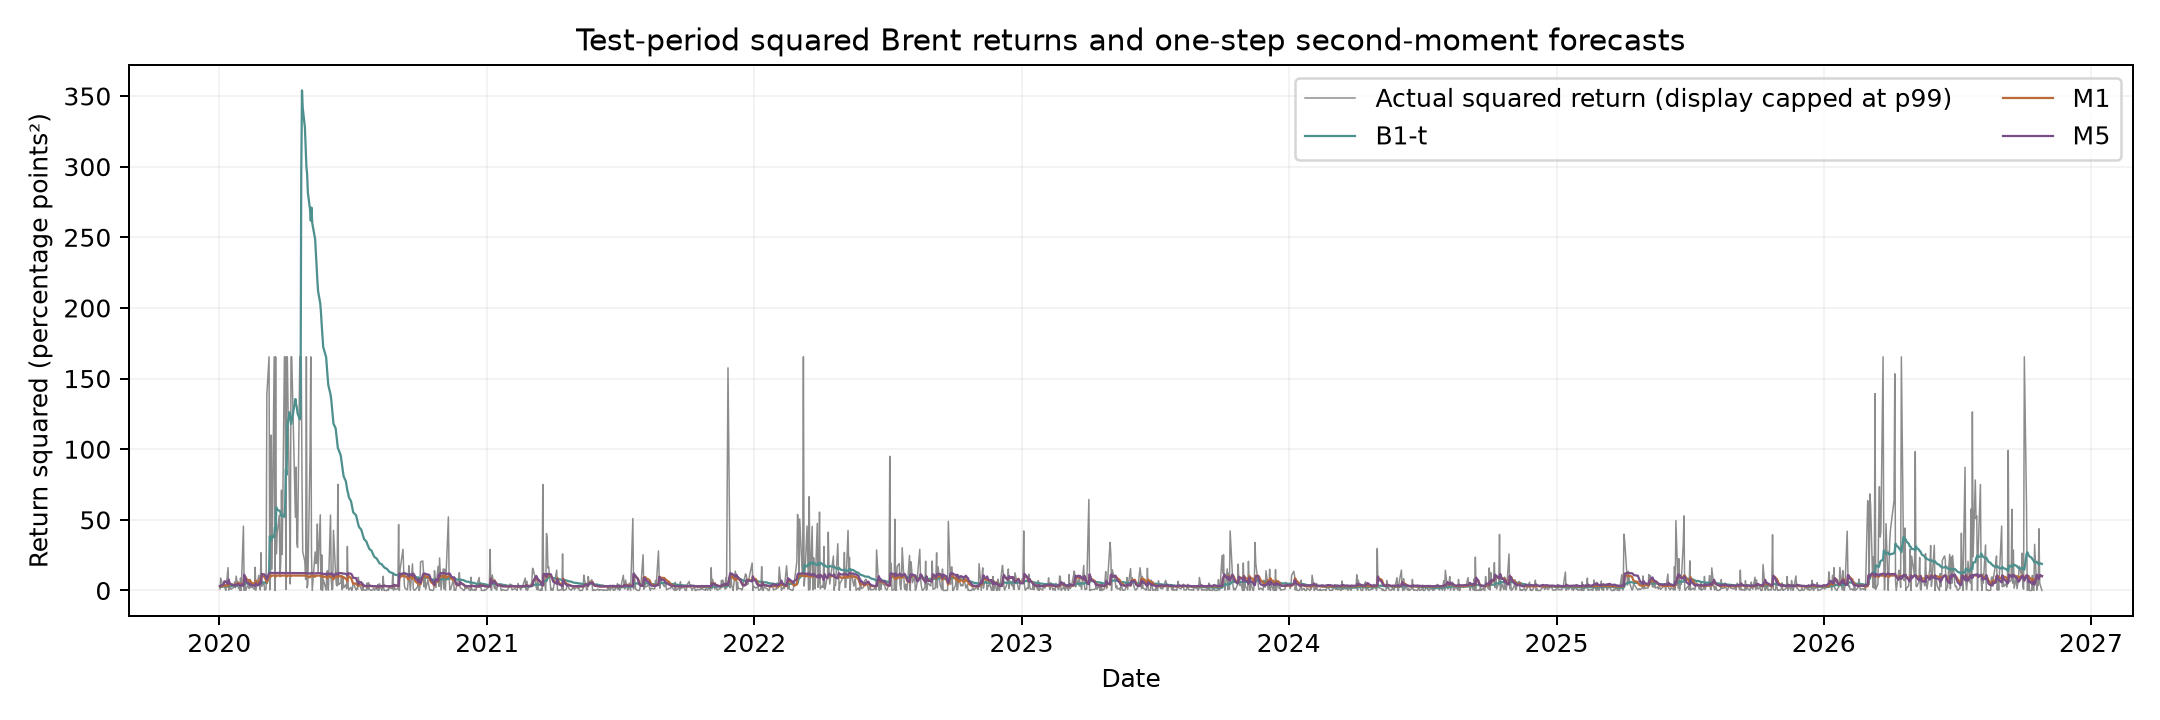

### 05_predicted_volatility.png

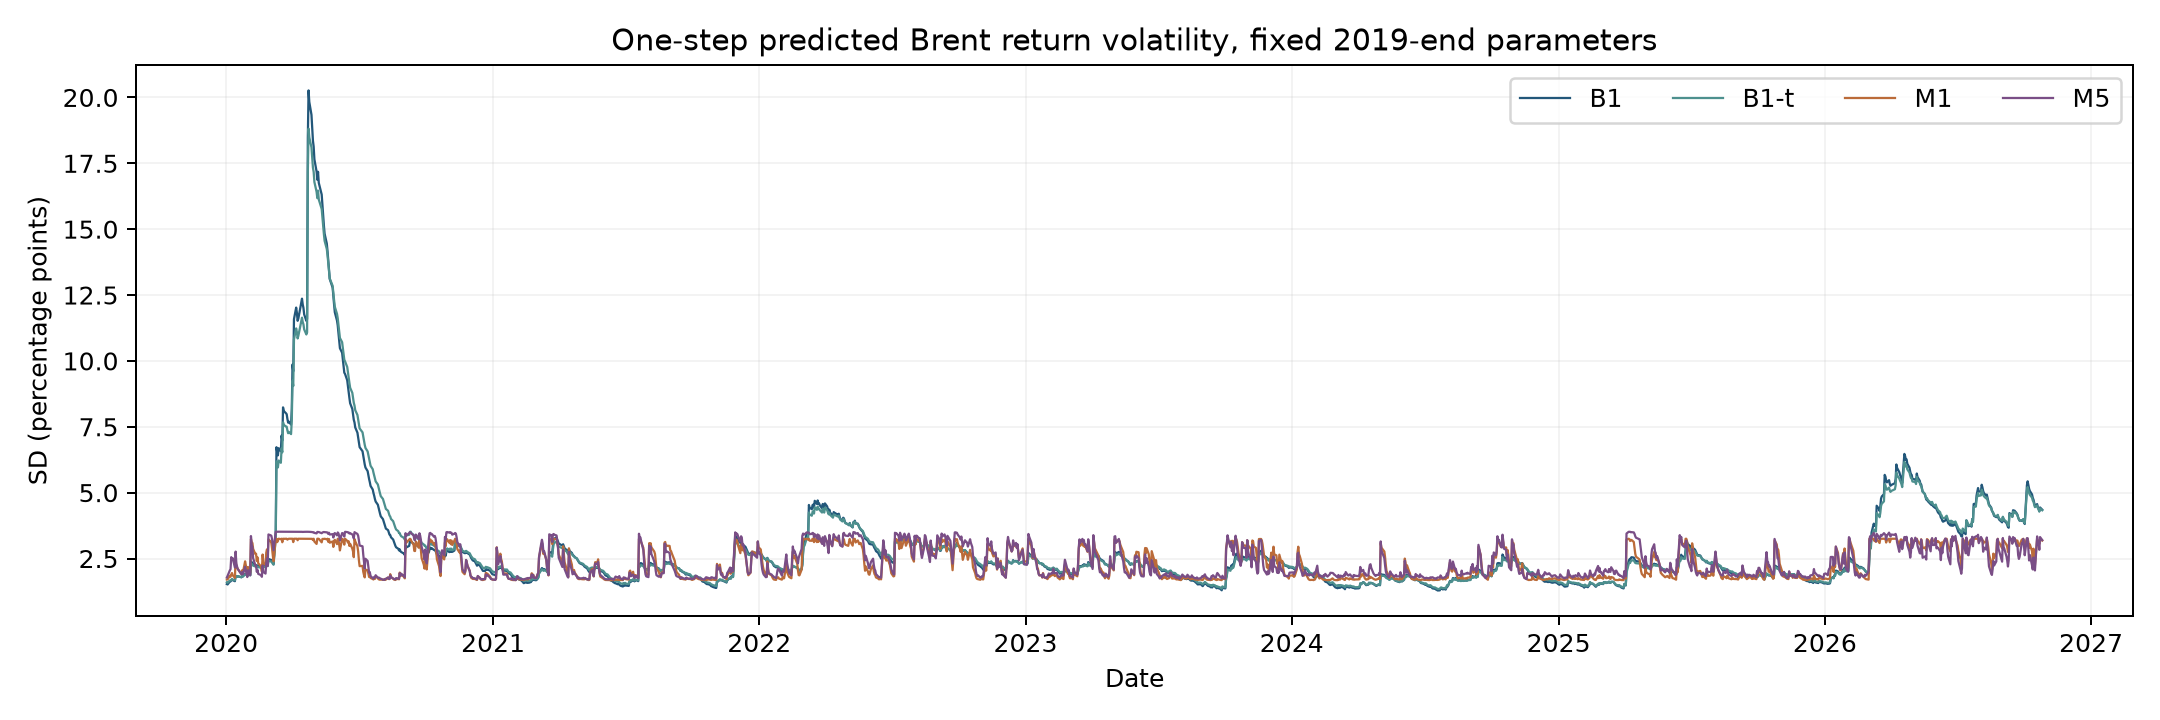

### 05_cumulative_qlike_difference.png

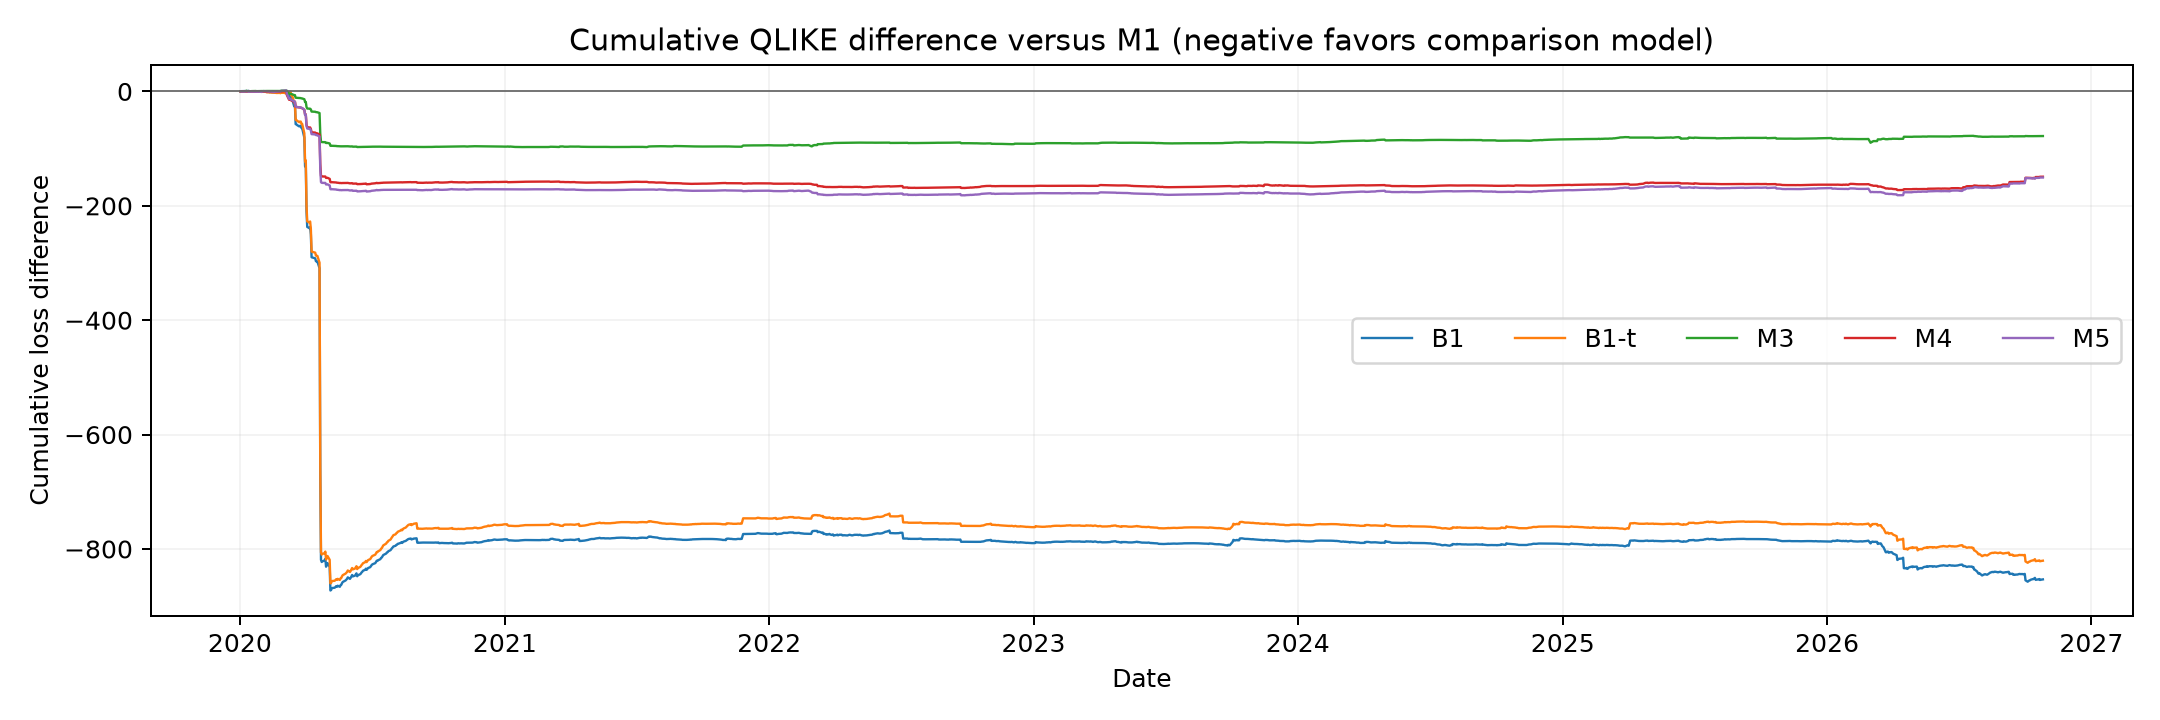

### 05_yearly_qlike.png

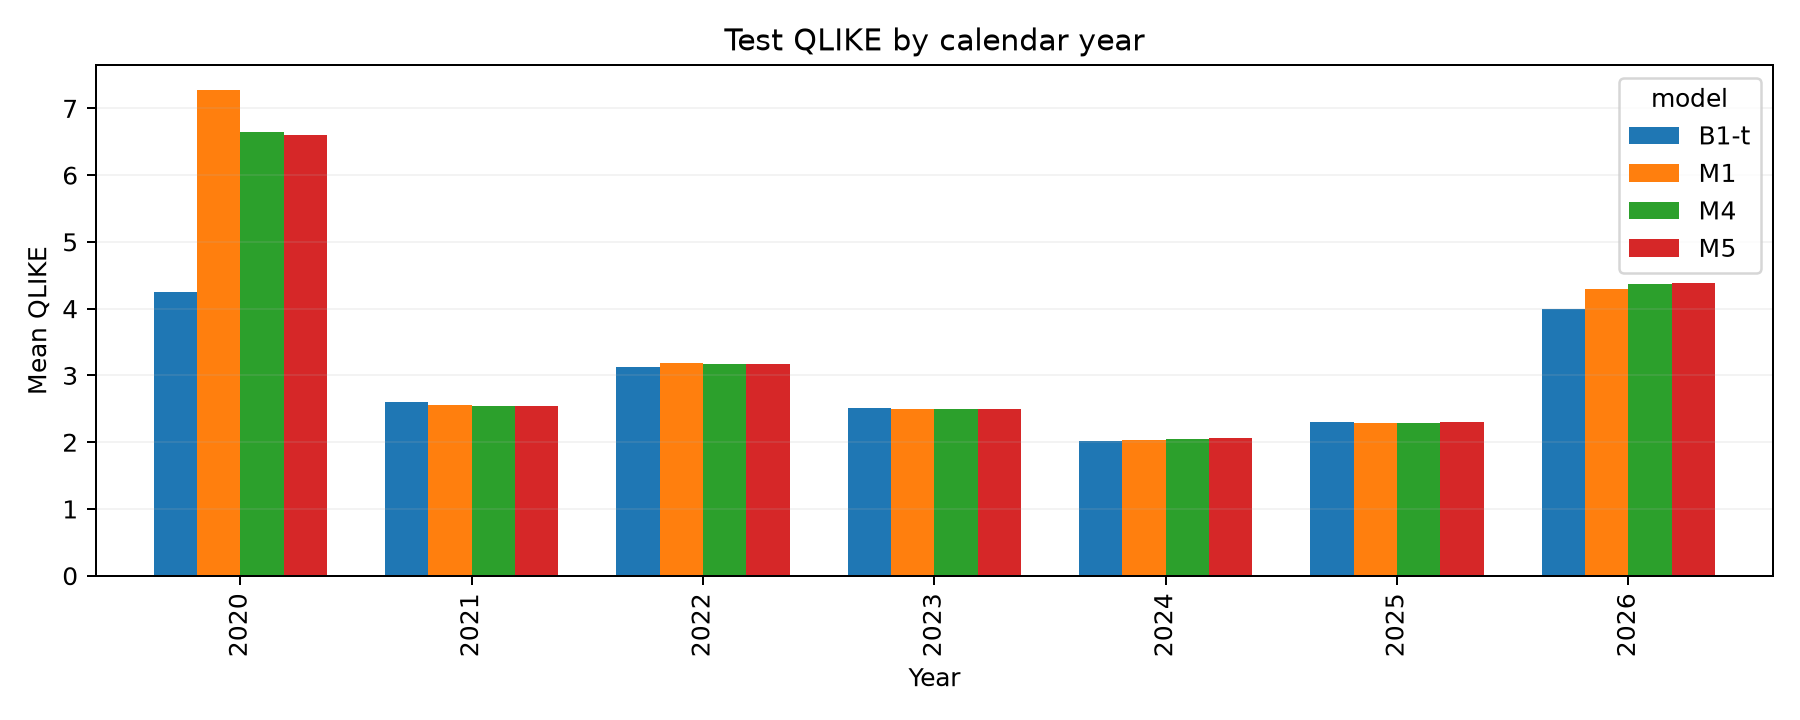

### 05_disruption_qlike.png

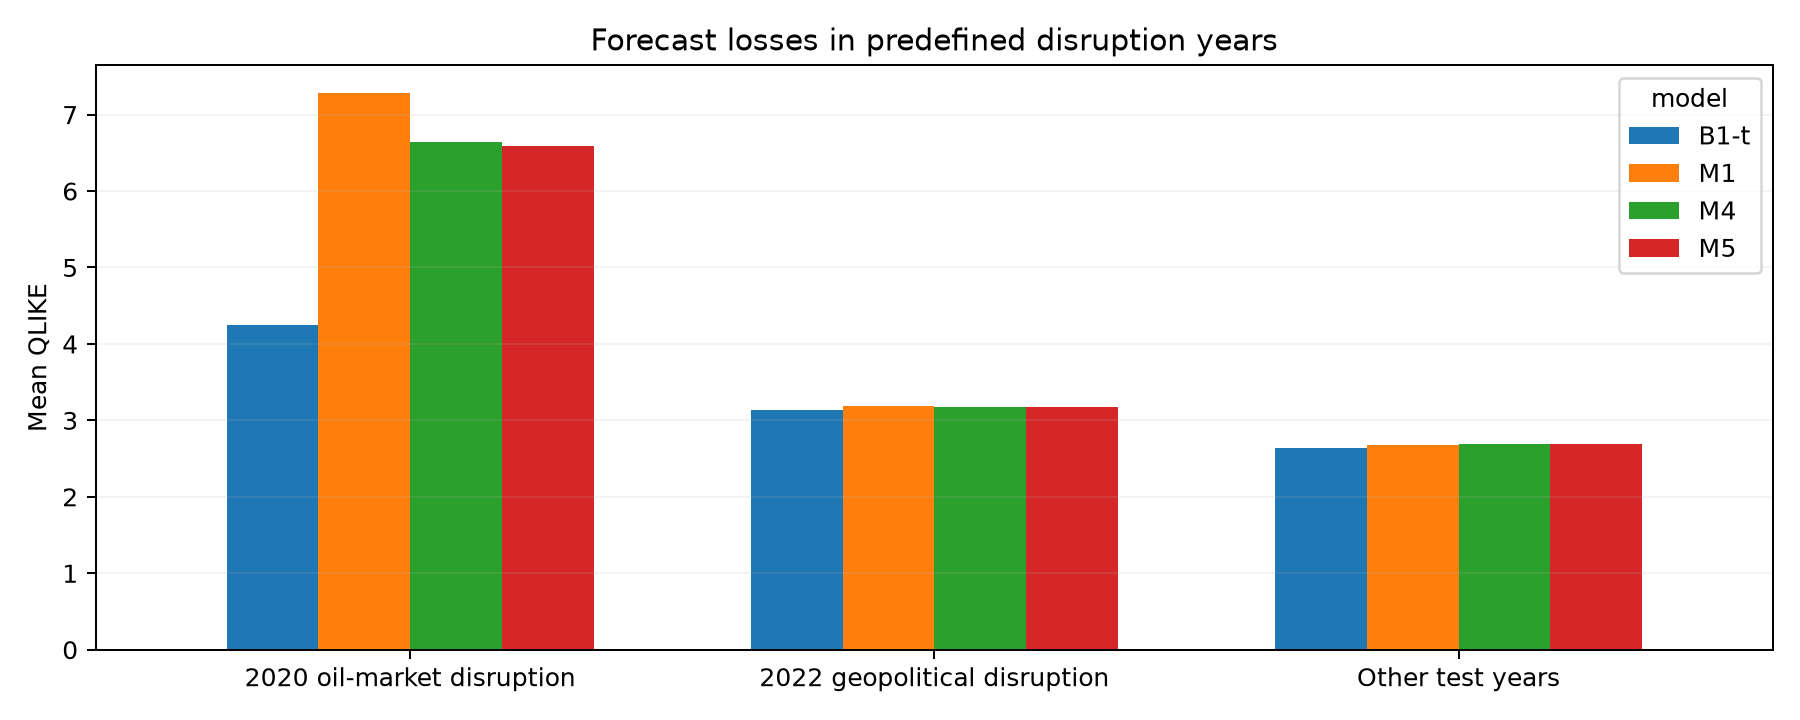

In [6]:
for filename in ["05_actual_vs_forecast.png", "05_predicted_volatility.png", "05_cumulative_qlike_difference.png", "05_yearly_qlike.png", "05_disruption_qlike.png"]:
    display(Markdown(f"### {filename}"))
    display(Image(filename=str(FIGURES / filename), width=900))

## Academic interpretation and Stage 05 gate

**Methodological gate: PASS.** All 7 models forecast the same 999 validation and 1,712 test dates. All primary and 2007-start estimates converged, all 42 recorded fitting attempts have zero estimation warnings, and the notebook's sequential state, transition, density, moment, positivity, scaling, and timing assertions passed. The final-test fit ends on 2019-12-31. GARCH estimates remain near integrated and the 2000–2006 irregular return intervals remain a limitation.

1. **M5 versus M1:** On validation, M5 QLIKE is 2.4450 versus M1 2.4420, a slight worsening. On test, M5 is 3.3356 versus M1 3.4235, a numerical improvement of 0.0879. The paired 10-observation block-bootstrap basic 95% interval for M1 minus M5 is −0.0473 to 0.1804 (centered p ≈ 0.122). A reliable out-of-sample advantage is therefore **not established**.
2. **Incremental GPR beyond VIX:** M5 and M4 test QLIKE are 3.3356 and 3.3364; the difference is about 0.0008. Validation favors M4 by about 0.0030. The test M4-minus-M5 interval is −0.0150 to 0.0131. There is no persuasive incremental GPR forecast gain.
3. **VIX versus GPR:** M4 has numerically lower QLIKE than M3 on validation (2.4420 versus 2.4478) and test (3.3364 versus 3.3780). This suggests VIX is the more useful of the two predictors for these models and periods, but this ranking is not itself a causal finding or a formal claim of significance.
4. **Markov versus GARCH:** On test, Gaussian GARCH has the lowest QLIKE (2.9252), while Student-t GARCH has the lowest negative log score (2.3346). M5 test QLIKE is 3.3356. The paired B1-minus-M5 QLIKE difference is −0.4105, but its basic interval (−0.8089, 0.2890) crosses zero. The average advantage is concentrated in shocks, so a statistically secure general advantage is not claimed.
5. **Extreme conditions and economic magnitude:** The 2020 full-calendar-year QLIKE is 6.5956 for M5 versus 4.1470 for B1; M5 improves on M1's 7.2795 but does not match GARCH. The 18 largest absolute test returns (top 1%) account for 17.8% of M5's total QLIKE sum, compared with 5.3% for B1. The 2020 dates account for 28.9% of M5's total test QLIKE sum. All observations are retained in the primary metrics; diagnostic exclusions are separate.
6. **Early-data sensitivity:** Refitting on 2007–2015 and evaluating the same validation dates worsens M5 QLIKE from 2.4450 to 2.5021 and M4 from 2.4420 to 2.5027. Thus the transition-model validation result is sensitive to training coverage. This sensitivity does not alter the pre-established primary sample or use test results for selection.
7. **GPR data limitation:** Historical revised GPR values and their assumed previous-calendar-day alignment were used. Because original publication vintages and release timing are unverified, these are historical pseudo-out-of-sample forecasts. They cannot be described as proven real-time predictions; model associations are not causal effects.

In-sample Stage 04 likelihood rankings describe fitted historical relationships. This Stage 05 evidence is the held-out predictive assessment. Its substantive result is mixed or negative for a special M5 advantage, despite numerically better M5 than M1 during the 2020 disruption. The 2026 yearly column is partial, ending 2026-10-26.
